<a href="https://colab.research.google.com/github/vanixcore/neurotwin/blob/main/NeuroTwin_AI_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NeuroTwin AI - Colab Edition
A small, fully runnable prototype inspired by the idea of a "digital brain" foundation model.

**Pipeline:** synthetic brain signals -> preprocessing -> Transformer brain encoder -> self-supervised masked pretraining -> future activity forecasting -> evaluation -> uncertainty -> export + inference.

**Important:** all data here is SYNTHETIC. This is a learning/portfolio prototype, not the Stanford model and not a clinical or diagnostic tool.



## Cell 1 - Imports, seed and device
**What this cell does:** imports all libraries, fixes random seeds for reproducibility, and picks GPU if available (otherwise CPU).

In [ ]:
import os, json, math, random
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, detrend
from sklearn.decomposition import PCA

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.11.0+cu130 | Device: cuda


## Cell 2 - Central configuration
**What this cell does:** defines every hyper-parameter in one dataclass (data size, window lengths, model size, training epochs) so experiments are easy to change and reproduce.

In [ ]:
@dataclass
class Cfg:
    # synthetic data
    n_subjects: int = 60
    n_regions: int = 16        # number of brain regions (ROIs)
    n_latents: int = 4         # hidden brain "networks" generating the signals
    T: int = 600               # time points per subject (1 sample = 1 TR = 1 second)
    # windowing
    ctx: int = 64              # context length the model sees
    horizon: int = 16          # how many future steps we predict
    stride: int = 8
    # model
    d_model: int = 64
    heads: int = 4
    layers: int = 2
    dropout: float = 0.1
    # training
    batch: int = 64
    pre_epochs: int = 15       # self-supervised pretraining epochs
    ft_epochs: int = 20        # forecasting fine-tuning epochs
    lr: float = 1e-3
    mask_ratio: float = 0.3
    patch: int = 4             # masked patch size (time steps)

cfg = Cfg()
print(cfg)

Cfg(n_subjects=60, n_regions=16, n_latents=4, T=600, ctx=64, horizon=16, stride=8, d_model=64, heads=4, layers=2, dropout=0.1, batch=64, pre_epochs=15, ft_epochs=20, lr=0.001, mask_ratio=0.3, patch=4)


## Cell 3 - Synthetic brain activity generator
**What this cell does:** creates fake fMRI-like data for 60 subjects x 16 regions x 600 time points. Signals come from 4 hidden oscillating networks mixed into regions, plus a stimulus-driven response (a block design convolved with a haemodynamic-like kernel), plus noise. Two subject groups (0 and 1) differ slightly in one network, so we can later check whether embeddings separate them.

In [ ]:
rng = np.random.default_rng(SEED)
R, K, T = cfg.n_regions, cfg.n_latents, cfg.T
roi_names = [f"ROI_{i:02d}" for i in range(R)]

# Shared "anatomy": region i mostly belongs to network i // (R/K)
W_base = 0.2 * rng.random((R, K))
for i in range(R):
    W_base[i, i // (R // K)] += 1.0

# Stimulus: 30 s ON / 60 s OFF blocks, convolved with a gamma-shaped haemodynamic response
t_hrf = np.arange(0, 30)
hrf = t_hrf**5 * np.exp(-t_hrf); hrf /= hrf.sum()
box = ((np.arange(T) % 90) < 30).astype(float)
stim = np.convolve(box, hrf)[:T]
stim = (stim - stim.mean()) / stim.std()
stim_w = np.zeros(R); stim_w[4:8] = 1.0          # "sensory" regions respond to the stimulus

freqs = np.array([0.02, 0.05, 0.09, 0.15])        # oscillation frequencies in Hz (TR = 1 s)

def make_subject(group):
    tt = np.arange(T)
    phases = rng.uniform(0, 2 * np.pi, K)
    lat = np.sin(2 * np.pi * freqs[None, :K] * tt[:, None] + phases[None, :])
    lat += 0.3 * rng.standard_normal(lat.shape)
    W = W_base + 0.15 * rng.standard_normal(W_base.shape)   # subject-specific variability
    if group == 1:
        W[: R // K, 0] *= 1.6                                # group effect on network 0
    x = lat @ W.T
    x += (stim[:, None] * stim_w[None, :]) * (1 + 0.2 * rng.standard_normal())
    x += 0.4 * rng.standard_normal(x.shape)                  # measurement noise
    x += np.linspace(0, 1, T)[:, None] * rng.normal(0, 0.5, R)   # slow scanner drift
    return x.astype(np.float32)

groups = np.array([i % 2 for i in range(cfg.n_subjects)])
raw = np.stack([make_subject(g) for g in groups])            # (subjects, time, regions)
print("Raw data shape (subjects, time, regions):", raw.shape)

Raw data shape (subjects, time, regions): (60, 600, 16)


## Cell 4 - Preprocessing (detrend, band-pass, z-score)
**What this cell does:** cleans each subject's signals like a real neuroimaging pipeline would: removes linear drift, applies a 0.01-0.2 Hz band-pass filter, then z-scores every region per subject so all regions are on the same scale.

In [ ]:
def preprocess(x, fs=1.0, low=0.01, high=0.2):
    """x: (time, regions) -> cleaned, z-scored (time, regions)."""
    x = detrend(x, axis=0)
    sos = butter(3, [low, high], btype="band", fs=fs, output="sos")
    x = sosfiltfilt(sos, x, axis=0)
    x = (x - x.mean(0, keepdims=True)) / (x.std(0, keepdims=True) + 1e-8)
    return x.astype(np.float32)

clean = np.stack([preprocess(s) for s in raw])
print("Clean data shape:", clean.shape, "| mean ~", clean.mean().round(4), "| std ~", clean.std().round(4))

Clean data shape: (60, 600, 16) | mean ~ -0.0 | std ~ 1.0


## Cell 5 - Subject-wise split and sliding windows
**What this cell does:** splits SUBJECTS (not windows) into train/val/test so no test subject is ever seen in training (prevents data leakage). Then cuts each subject's time series into overlapping windows of `ctx + horizon` steps: the first `ctx` are input, the last `horizon` are the forecast target.

In [ ]:
perm = np.random.default_rng(SEED).permutation(cfg.n_subjects)
n_tr, n_va = int(0.7 * cfg.n_subjects), int(0.15 * cfg.n_subjects)
split = {"train": perm[:n_tr], "val": perm[n_tr:n_tr + n_va], "test": perm[n_tr + n_va:]}

def make_windows(subj_ids):
    L = cfg.ctx + cfg.horizon
    wins, sid = [], []
    for s in subj_ids:
        for start in range(0, cfg.T - L + 1, cfg.stride):
            wins.append(clean[s, start:start + L]); sid.append(s)
    return torch.tensor(np.stack(wins)), np.array(sid)

data, win_subj = {}, {}
for name, ids in split.items():
    data[name], win_subj[name] = make_windows(ids)
    print(f"{name:5s}: {len(ids):2d} subjects -> windows {tuple(data[name].shape)}")
assert not (set(split["train"]) & set(split["test"])), "Leakage: subject overlap!"
print("No subject overlap between train and test: OK")

train: 42 subjects -> windows (2772, 80, 16)
val  :  9 subjects -> windows (594, 80, 16)
test :  9 subjects -> windows (594, 80, 16)
No subject overlap between train and test: OK


## Cell 6 - Look at the data
**What this cell does:** plots (1) raw vs preprocessed signal of one region, (2) the region x time activity heatmap of one subject, and (3) the region-to-region correlation matrix (functional connectivity), where the 4 hidden networks should appear as blocks.

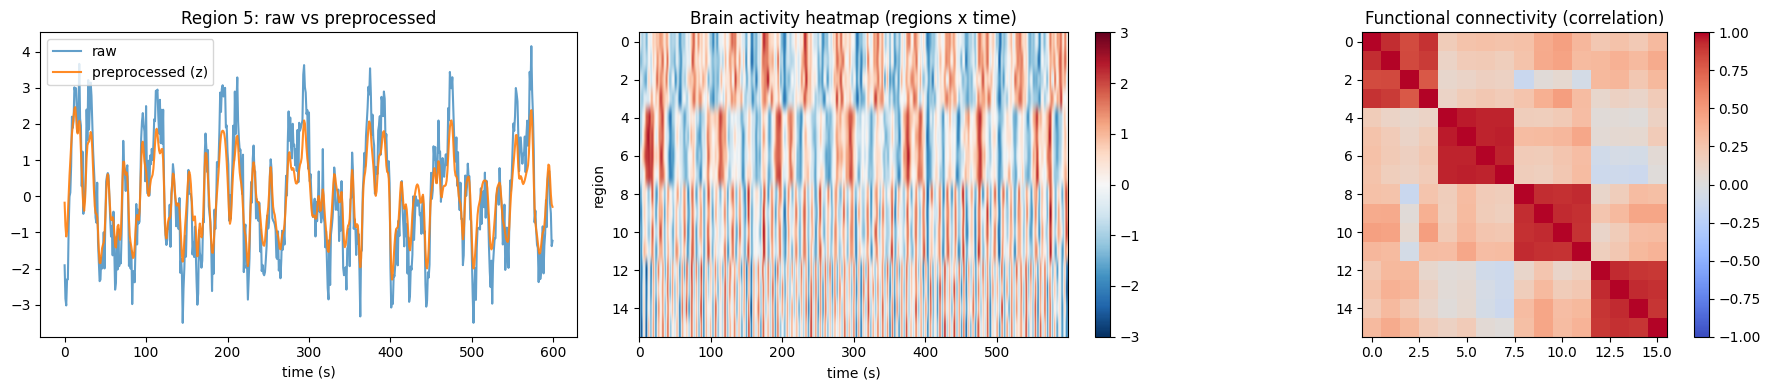

In [ ]:
s0 = 0
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(raw[s0, :, 5], label="raw", alpha=0.7)
ax[0].plot(clean[s0, :, 5], label="preprocessed (z)", alpha=0.9)
ax[0].set_title("Region 5: raw vs preprocessed"); ax[0].set_xlabel("time (s)"); ax[0].legend()

im = ax[1].imshow(clean[s0].T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax[1].set_title("Brain activity heatmap (regions x time)"); ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("region")
plt.colorbar(im, ax=ax[1])

conn = np.corrcoef(clean[s0].T)
im2 = ax[2].imshow(conn, cmap="coolwarm", vmin=-1, vmax=1)
ax[2].set_title("Functional connectivity (correlation)"); plt.colorbar(im2, ax=ax[2])
plt.tight_layout(); plt.show()

## Cell 7 - Brain foundation model (Transformer encoder)
**What this cell does:** defines the model. Each time step (a vector of 16 region values) is projected to a token, positional embeddings are added, and a Transformer encoder models temporal dependencies. Two heads share this encoder: a **reconstruction head** (for masked self-supervised pretraining) and a **forecast head** (predicts the next `horizon` steps for all regions).

In [ ]:
class BrainEncoder(nn.Module):
    def __init__(self, c: Cfg):
        super().__init__()
        self.c = c
        self.inp = nn.Linear(c.n_regions, c.d_model)
        self.pos = nn.Parameter(torch.randn(1, c.ctx, c.d_model) * 0.02)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, c.d_model))
        layer = nn.TransformerEncoderLayer(
            d_model=c.d_model, nhead=c.heads, dim_feedforward=c.d_model * 4,
            dropout=c.dropout, batch_first=True, activation="gelu", norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=c.layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(c.d_model)
        self.recon_head = nn.Linear(c.d_model, c.n_regions)
        self.forecast_head = nn.Sequential(
            nn.Linear(c.d_model, c.d_model), nn.GELU(),
            nn.Linear(c.d_model, c.horizon * c.n_regions))

    def encode(self, x, mask=None):
        h = self.inp(x)
        if mask is not None:                      # replace masked time steps by a learned token
            h = torch.where(mask.unsqueeze(-1), self.mask_token.expand_as(h), h)
        return self.norm(self.encoder(h + self.pos))

    def reconstruct(self, x, mask):
        return self.recon_head(self.encode(x, mask))

    def forecast(self, x):
        h = self.encode(x)
        z = h.mean(1) + h[:, -1]                  # global summary + most recent state
        return self.forecast_head(z).view(-1, self.c.horizon, self.c.n_regions)

model = BrainEncoder(cfg).to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 127184


## Cell 8 - Self-supervised pretraining (masked reconstruction)
**What this cell does:** trains the encoder WITHOUT any forecasting labels. Random patches of time steps are hidden and the model must reconstruct them from the surrounding context. Loss is computed only on the hidden steps. This is the "foundation model" idea: learn general brain-signal structure first.

In [ ]:
def random_patch_mask(B, L, patch, ratio, dev):
    n_patches = L // patch
    m = torch.rand(B, n_patches, device=dev) < ratio
    return m.repeat_interleave(patch, dim=1)       # (B, L) boolean

def batches(x, bs, shuffle=True):
    idx = torch.randperm(len(x)) if shuffle else torch.arange(len(x))
    for i in range(0, len(x), bs):
        yield x[idx[i:i + bs]]

def pretrain(model, epochs):
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=1e-4)
    hist = {"train": [], "val": []}
    for ep in range(epochs):
        model.train(); tl, n = 0.0, 0
        for xb in batches(data["train"][:, :cfg.ctx], cfg.batch):
            xb = xb.to(device)
            m = random_patch_mask(len(xb), cfg.ctx, cfg.patch, cfg.mask_ratio, device)
            pred = model.reconstruct(xb, m)
            loss = ((pred - xb) ** 2)[m].mean()    # loss only on masked positions
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tl += loss.item() * len(xb); n += len(xb)
        model.eval(); vl, vn = 0.0, 0
        with torch.no_grad():
            for xb in batches(data["val"][:, :cfg.ctx], 256, shuffle=False):
                xb = xb.to(device)
                m = random_patch_mask(len(xb), cfg.ctx, cfg.patch, cfg.mask_ratio, device)
                vl += ((model.reconstruct(xb, m) - xb) ** 2)[m].mean().item() * len(xb); vn += len(xb)
        hist["train"].append(tl / n); hist["val"].append(vl / vn)
        print(f"[pretrain] epoch {ep+1:2d}/{epochs}  train={hist['train'][-1]:.4f}  val={hist['val'][-1]:.4f}")
    return hist

pre_hist = pretrain(model, cfg.pre_epochs)

[pretrain] epoch  1/15  train=0.9886  val=0.9653
[pretrain] epoch  2/15  train=0.9482  val=0.9261
[pretrain] epoch  3/15  train=0.9111  val=0.9092
[pretrain] epoch  4/15  train=0.8926  val=0.8701
[pretrain] epoch  5/15  train=0.8767  val=0.8536
[pretrain] epoch  6/15  train=0.8356  val=0.7955
[pretrain] epoch  7/15  train=0.7705  val=0.7366
[pretrain] epoch  8/15  train=0.7433  val=0.7083
[pretrain] epoch  9/15  train=0.6954  val=0.6229
[pretrain] epoch 10/15  train=0.5949  val=0.5485
[pretrain] epoch 11/15  train=0.5645  val=0.5286
[pretrain] epoch 12/15  train=0.5506  val=0.5236
[pretrain] epoch 13/15  train=0.5427  val=0.5108
[pretrain] epoch 14/15  train=0.5341  val=0.5093
[pretrain] epoch 15/15  train=0.5262  val=0.4986


## Cell 9 - Fine-tune for forecasting (and an ablation without pretraining)
**What this cell does:** trains the forecast head (and the encoder) to predict the next 16 time steps from the previous 64, keeping the best checkpoint by validation loss. To test whether pretraining really helps, it ALSO trains an identical model from scratch with no pretraining, so we can compare them fairly in the evaluation cell.

In [ ]:
def finetune(model, epochs, lr=5e-4, tag="finetune"):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    best, best_state = float("inf"), None
    hist = {"train": [], "val": []}
    for ep in range(epochs):
        model.train(); tl, n = 0.0, 0
        for wb in batches(data["train"], cfg.batch):
            wb = wb.to(device)
            x, y = wb[:, :cfg.ctx], wb[:, cfg.ctx:]
            loss = nn.functional.mse_loss(model.forecast(x), y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tl += loss.item() * len(wb); n += len(wb)
        model.eval(); vl, vn = 0.0, 0
        with torch.no_grad():
            for wb in batches(data["val"], 256, shuffle=False):
                wb = wb.to(device)
                vl += nn.functional.mse_loss(model.forecast(wb[:, :cfg.ctx]), wb[:, cfg.ctx:]).item() * len(wb); vn += len(wb)
        hist["train"].append(tl / n); hist["val"].append(vl / vn)
        if hist["val"][-1] < best:
            best = hist["val"][-1]; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"[{tag}] epoch {ep+1:2d}/{epochs}  train={hist['train'][-1]:.4f}  val={hist['val'][-1]:.4f}")
    model.load_state_dict(best_state)
    return hist

ft_hist = finetune(model, cfg.ft_epochs, tag="pretrained")

torch.manual_seed(SEED + 1)
scratch = BrainEncoder(cfg).to(device)               # same architecture, NO pretraining
scratch_hist = finetune(scratch, cfg.ft_epochs, tag="scratch")

[pretrained] epoch  1/20  train=0.9341  val=0.8058
[pretrained] epoch  2/20  train=0.6704  val=0.5053
[pretrained] epoch  3/20  train=0.4497  val=0.3726
[pretrained] epoch  4/20  train=0.3453  val=0.2931
[pretrained] epoch  5/20  train=0.2927  val=0.2659
[pretrained] epoch  6/20  train=0.2697  val=0.2452
[pretrained] epoch  7/20  train=0.2508  val=0.2327
[pretrained] epoch  8/20  train=0.2388  val=0.2193
[pretrained] epoch  9/20  train=0.2292  val=0.2176
[pretrained] epoch 10/20  train=0.2241  val=0.2078
[pretrained] epoch 11/20  train=0.2205  val=0.2104
[pretrained] epoch 12/20  train=0.2183  val=0.2079
[pretrained] epoch 13/20  train=0.2151  val=0.2086
[pretrained] epoch 14/20  train=0.2141  val=0.2060
[pretrained] epoch 15/20  train=0.2130  val=0.2034
[pretrained] epoch 16/20  train=0.2102  val=0.2034
[pretrained] epoch 17/20  train=0.2108  val=0.2006
[pretrained] epoch 18/20  train=0.2079  val=0.2022
[pretrained] epoch 19/20  train=0.2076  val=0.2019
[pretrained] epoch 20/20  train

## Cell 10 - Loss curves
**What this cell does:** plots the pretraining loss and the forecasting loss (pretrained vs from-scratch) so you can see convergence and whether pretraining helped.

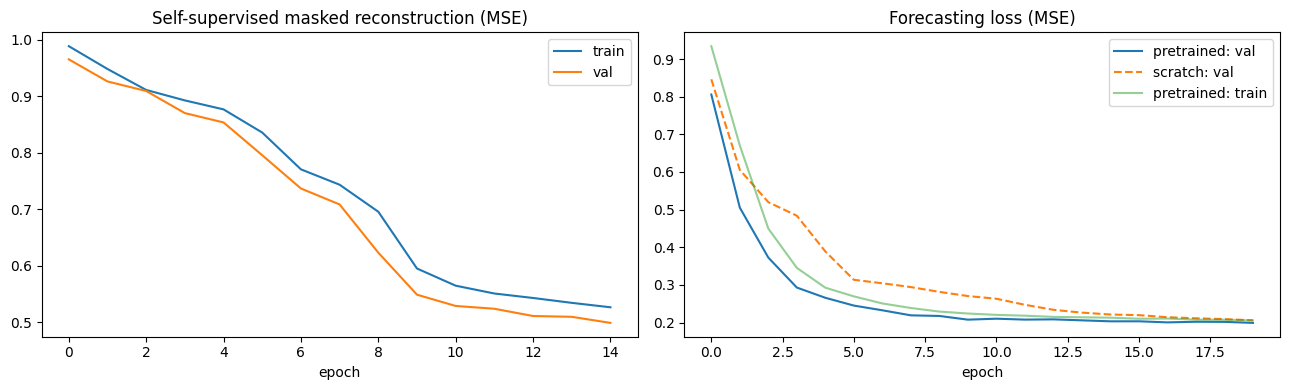

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(pre_hist["train"], label="train"); ax[0].plot(pre_hist["val"], label="val")
ax[0].set_title("Self-supervised masked reconstruction (MSE)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ft_hist["val"], label="pretrained: val"); ax[1].plot(scratch_hist["val"], label="scratch: val", linestyle="--")
ax[1].plot(ft_hist["train"], label="pretrained: train", alpha=0.5)
ax[1].set_title("Forecasting loss (MSE)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## Cell 11 - Evaluation on held-out test subjects
**What this cell does:** computes MAE, RMSE and R2 on subjects the model never saw, and compares against two simple baselines: **persistence** (repeat the last value) and **context mean** (predict the mean of the input window). A model is only useful if it beats these baselines.

In [ ]:
@torch.no_grad()
def predict(m, x, bs=256):
    m.eval(); out = []
    for i in range(0, len(x), bs):
        out.append(m.forecast(x[i:i + bs].to(device)).cpu())
    return torch.cat(out)

def metrics(pred, true):
    err = (pred - true).numpy().ravel(); t = true.numpy().ravel()
    mae = np.abs(err).mean(); rmse = math.sqrt((err ** 2).mean())
    r2 = 1 - (err ** 2).sum() / ((t - t.mean()) ** 2).sum()
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

xt, yt = data["test"][:, :cfg.ctx], data["test"][:, cfg.ctx:]
preds = {
    "NeuroTwin (pretrained)": predict(model, xt),
    "Transformer (no pretraining)": predict(scratch, xt),
    "Baseline: persistence": xt[:, -1:, :].repeat(1, cfg.horizon, 1),
    "Baseline: context mean": xt.mean(1, keepdim=True).repeat(1, cfg.horizon, 1),
}
results = pd.DataFrame({k: metrics(v, yt) for k, v in preds.items()}).T.round(4)
display(results) if "display" in globals() else print(results)

                                 MAE    RMSE      R2
NeuroTwin (pretrained)        0.3634  0.4636  0.7807
Transformer (no pretraining)  0.3693  0.4709  0.7737
Baseline: persistence         1.0494  1.3031 -0.7329
Baseline: context mean        0.8793  1.0402 -0.1041


## Cell 12 - Actual vs predicted signals
**What this cell does:** picks a few test windows and plots the input context, the true future signal and the model's predicted future for selected regions.

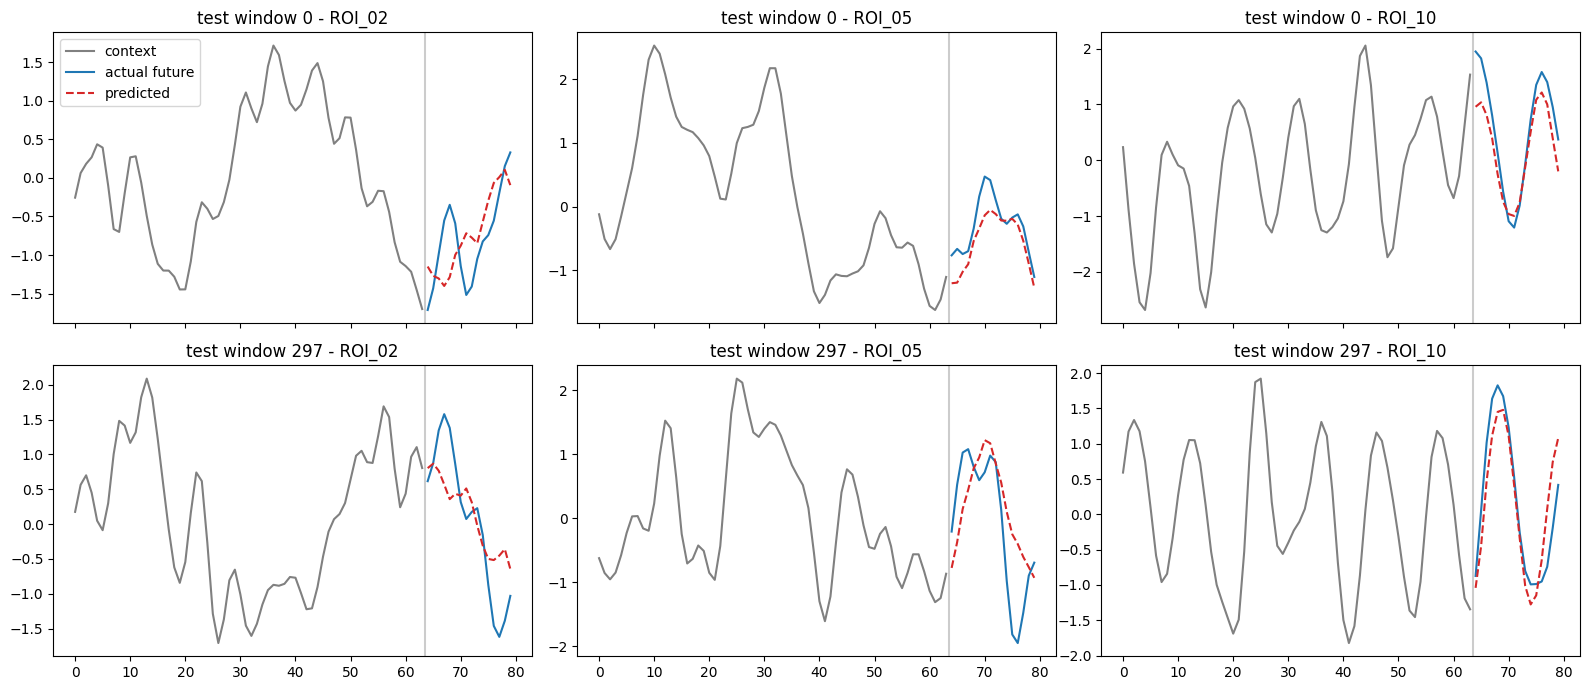

In [ ]:
pred_best = preds["NeuroTwin (pretrained)"]
regions_to_show, windows_to_show = [2, 5, 10], [0, len(xt) // 2]
fig, axes = plt.subplots(len(windows_to_show), len(regions_to_show), figsize=(16, 7), sharex=True)
tc = np.arange(cfg.ctx); tf = np.arange(cfg.ctx, cfg.ctx + cfg.horizon)
for r_i, w in enumerate(windows_to_show):
    for c_i, reg in enumerate(regions_to_show):
        a = axes[r_i, c_i]
        a.plot(tc, xt[w, :, reg], color="gray", label="context")
        a.plot(tf, yt[w, :, reg], color="tab:blue", label="actual future")
        a.plot(tf, pred_best[w, :, reg], color="tab:red", linestyle="--", label="predicted")
        a.axvline(cfg.ctx - 0.5, color="k", alpha=0.2)
        a.set_title(f"test window {w} - {roi_names[reg]}")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

## Cell 13 - Per-region error and prediction horizon analysis
**What this cell does:** shows where the model is strong or weak: RMSE for each brain region, and how error grows as we predict further into the future.

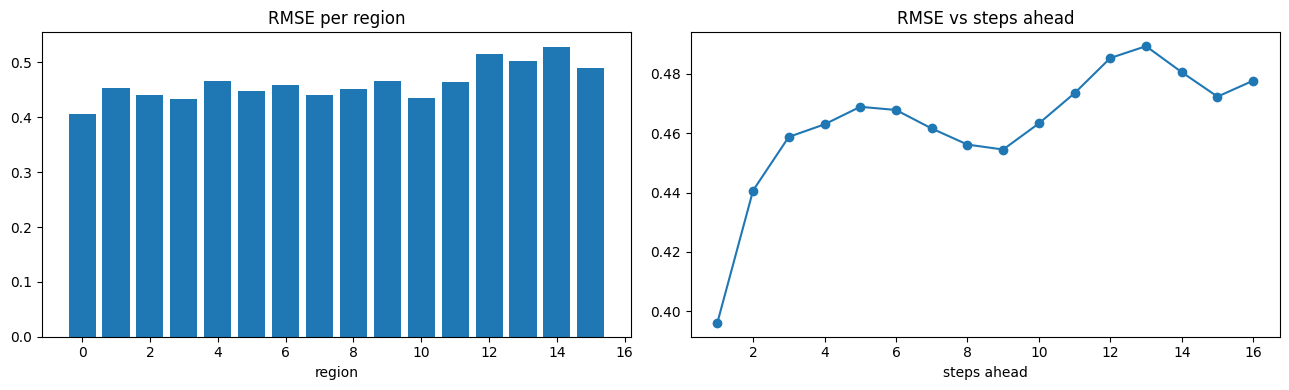

In [ ]:
err = (pred_best - yt).numpy()
rmse_region = np.sqrt((err ** 2).mean(axis=(0, 1)))
rmse_step = np.sqrt((err ** 2).mean(axis=(0, 2)))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(R), rmse_region); ax[0].set_title("RMSE per region"); ax[0].set_xlabel("region")
ax[1].plot(range(1, cfg.horizon + 1), rmse_step, marker="o"); ax[1].set_title("RMSE vs steps ahead"); ax[1].set_xlabel("steps ahead")
plt.tight_layout(); plt.show()

## Cell 14 - Learned brain embeddings
**What this cell does:** extracts the encoder's internal representation of every test window, reduces it to 2D with PCA, and colours points by subject group (0/1). If the foundation model learned something meaningful, the groups should show some separation even though group labels were never used in training.

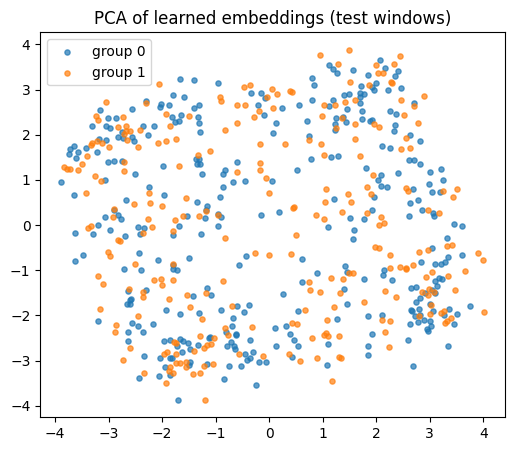

In [ ]:
@torch.no_grad()
def embed(m, x, bs=256):
    m.eval(); out = []
    for i in range(0, len(x), bs):
        out.append(m.encode(x[i:i + bs].to(device)).mean(1).cpu())
    return torch.cat(out).numpy()

emb = embed(model, xt)
emb2 = PCA(n_components=2, random_state=SEED).fit_transform(emb)
g = groups[win_subj["test"]]
plt.figure(figsize=(6, 5))
for gi, col in [(0, "tab:blue"), (1, "tab:orange")]:
    plt.scatter(emb2[g == gi, 0], emb2[g == gi, 1], s=14, alpha=0.7, c=col, label=f"group {gi}")
plt.title("PCA of learned embeddings (test windows)"); plt.legend(); plt.show()

## Cell 15 - Uncertainty with Monte-Carlo dropout
**What this cell does:** keeps dropout active at inference and runs the model 30 times to get a mean prediction and a standard deviation (an uncertainty band). It then checks how often the true signal falls inside the +/-2 std band (a simple calibration check).

Fraction of true values inside +/-2 std band: 29.03%  (well-calibrated ~95%)


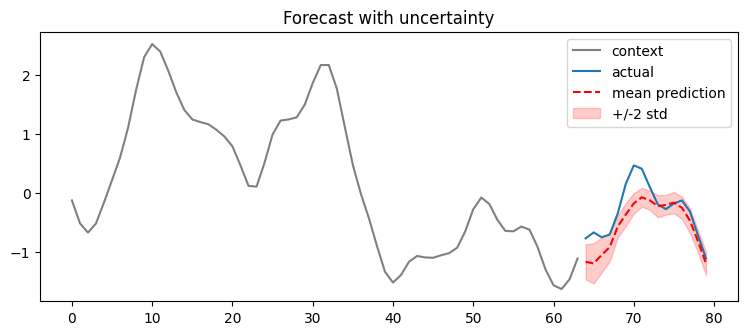

In [ ]:
@torch.no_grad()
def mc_predict(m, x, n=30):
    m.train()                                     # dropout ON
    outs = torch.stack([m.forecast(x.to(device)).cpu() for _ in range(n)])
    m.eval()
    return outs.mean(0), outs.std(0)

mu, sd = mc_predict(model, xt[:200])
inside = ((yt[:200] >= mu - 2 * sd) & (yt[:200] <= mu + 2 * sd)).float().mean().item()
print(f"Fraction of true values inside +/-2 std band: {inside:.2%}  (well-calibrated ~95%)")

w, reg = 0, 5
plt.figure(figsize=(9, 3.5))
plt.plot(tc, xt[w, :, reg], color="gray", label="context")
plt.plot(tf, yt[w, :, reg], label="actual")
plt.plot(tf, mu[w, :, reg], "r--", label="mean prediction")
plt.fill_between(tf, (mu - 2 * sd)[w, :, reg], (mu + 2 * sd)[w, :, reg], color="r", alpha=0.2, label="+/-2 std")
plt.title("Forecast with uncertainty"); plt.legend(); plt.show()

## Cell 16 - Export the trained model
**What this cell does:** saves the model weights together with the config into a single `.pt` file and writes the metrics to JSON, so the model can be reloaded later or downloaded from Colab.

In [ ]:
ckpt_path = "neurotwin_colab.pt"
torch.save({"state_dict": model.state_dict(), "cfg": asdict(cfg)}, ckpt_path)
results.to_json("neurotwin_metrics.json", indent=2)
print("Saved:", ckpt_path, f"({os.path.getsize(ckpt_path)/1e3:.0f} KB) and neurotwin_metrics.json")

try:
    from google.colab import files
    files.download(ckpt_path)                    # triggers a browser download when running in Colab
except Exception as e:
    print("Not running in Colab (or download blocked):", type(e).__name__)

Saved: neurotwin_colab.pt (523 KB) and neurotwin_metrics.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cell 17 - Inference on new data
**What this cell does:** reloads the saved checkpoint into a fresh model and defines `forecast_brain(signal)`, which takes ANY raw array of shape (time, 16 regions), preprocesses it the same way as training, and returns the next 16 predicted steps (in z-scored units). It also verifies the reloaded model matches the original.

Forecast shape: (16, 16) | reload matches original: True


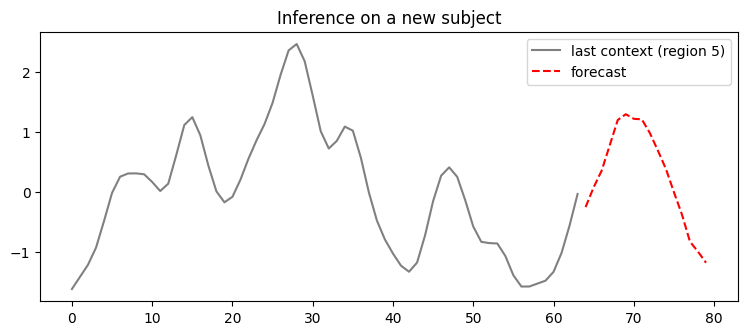

In [ ]:
def load_model(path):
    ck = torch.load(path, map_location=device)
    c = Cfg(**ck["cfg"]); m = BrainEncoder(c).to(device)
    m.load_state_dict(ck["state_dict"]); m.eval()
    return m, c

def forecast_brain(signal, m, c):
    """signal: np.ndarray (time >= ctx, n_regions) raw values. Returns (horizon, n_regions) z-scored forecast."""
    x = preprocess(np.asarray(signal, dtype=np.float32))[-c.ctx:]
    with torch.no_grad():
        return m.forecast(torch.tensor(x).unsqueeze(0).to(device)).cpu().numpy()[0]

loaded, loaded_cfg = load_model(ckpt_path)
new_subject = make_subject(group=1)               # a brand-new synthetic subject
fc = forecast_brain(new_subject, loaded, loaded_cfg)
same = forecast_brain(new_subject, model.eval(), cfg)
print("Forecast shape:", fc.shape, "| reload matches original:", np.allclose(fc, same, atol=1e-5))

plt.figure(figsize=(9, 3.5))
ctx_sig = preprocess(new_subject)[-cfg.ctx:, 5]
plt.plot(range(cfg.ctx), ctx_sig, color="gray", label="last context (region 5)")
plt.plot(range(cfg.ctx, cfg.ctx + cfg.horizon), fc[:, 5], "r--", label="forecast")
plt.title("Inference on a new subject"); plt.legend(); plt.show()

## Limitations and next steps
- Data is synthetic; real fMRI/MEG needs BIDS loading (e.g. `nilearn`, `mne`, OpenNeuro) and proper motion/QC handling.
- Real results would need cross-dataset validation, stronger baselines (e.g. VAR, LSTM) and statistical testing.
- This is a research prototype: no diagnosis, no treatment advice, not a medical device.

**Next steps to scale up:** load a real OpenNeuro dataset into the same `(subjects, time, regions)` format (e.g. via an atlas parcellation with `nilearn`), then re-run Cells 4-17 unchanged.